# Spine Chart (opposing bars)

**Family:** Deviation &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Basic

> *Deviation:* Emphasise variations (+/-) from a fixed reference point: zero, a target, or an average.

## Design purpose

Two sets of bars extend in opposite directions from a central spine. It splits one total into two opposing components (for example, for vs. against, or imports vs. exports) for each category.

## When to use

- Show two opposing components per category (wins/losses, inflow/outflow, men/women)
- Show each category's balance and its gross volume together

## Avoid when

- The two components are not opposites
- The categories are age bands (that is a population pyramid; see Distribution)

## Alternatives

- Grouped bar chart
- Dumbbell chart

## Design tips

- Use the same scale on both sides and label the ticks with absolute values
- Sort categories by total volume so the largest partners sit on top
- Give the two sides clearly different hues and name them in the axis label or legend

## Example

Imports and exports of a country by trade partner (USD bn), synthetic data.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
partners = ["China", "USA", "Japan", "Germany", "Korea", "Vietnam", "India", "Brazil"]
exports = np.array([120, 95, 40, 28, 25, 18, 12, 8])
imports = np.array([140, 70, 52, 30, 33, 10, 15, 11])
df = pd.DataFrame({"partner": partners, "exports": exports, "imports": imports})
df = df.iloc[::-1]
df

,partner,exports,imports
7,Brazil,8,11
6,India,12,15
5,Vietnam,18,10
4,Korea,25,33
3,Germany,28,30
2,Japan,40,52
1,USA,95,70
0,China,120,140


### Plot

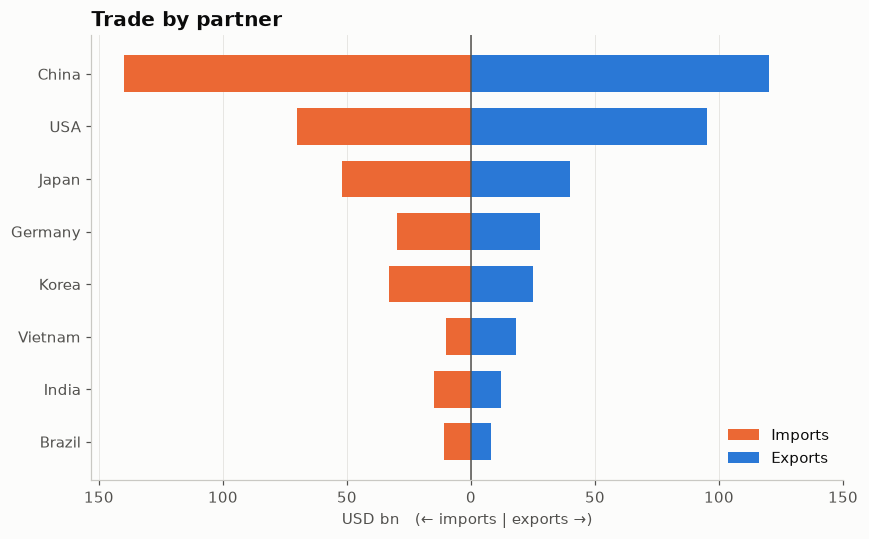

In [3]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(df["partner"], -df["imports"], color=PALETTE[1], label="Imports", height=0.7)
ax.barh(df["partner"], df["exports"], color=PALETTE[0], label="Exports", height=0.7)
ax.axvline(0, color="#52514e", linewidth=1)
ticks = np.arange(-150, 151, 50)
ax.set_xticks(ticks, [f"{abs(t)}" for t in ticks])
ax.set_xlabel("USD bn   (← imports | exports →)")
ax.set_title("Trade by partner")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

## How to read it

Orange bars to the left are imports and blue bars to the right are exports. China is the largest partner and runs a deficit (imports 140 vs. exports 120). The USA and Vietnam are the only partners where exports exceed imports.

---
Standalone script: [`spine_chart.py`](spine_chart.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)